<a href="https://colab.research.google.com/github/tqd3pz/ds2002-fa26/blob/main/notebooks/06-midterm-walmart/2026-10-28%20%E2%80%94%20Midterm%20Clinic%20Analysis%20and%20Charts%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

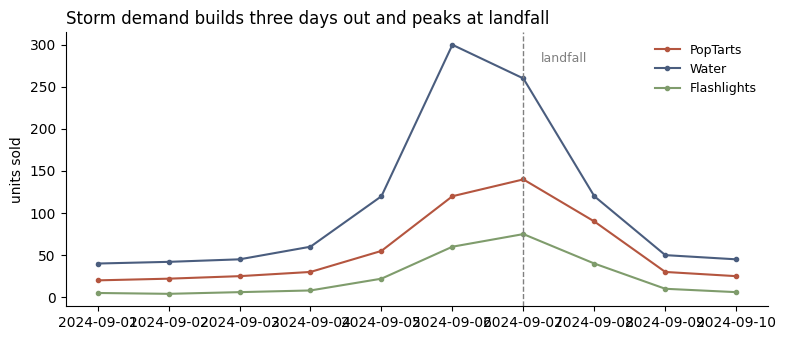

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

In [5]:
# TODO

import pandas as pd
import matplotlib.pyplot as plt

# Load and clean the Walmart data
df = pd.read_csv("/content/walmart_transactions.csv")

clean_df = df.drop_duplicates().copy()

clean_df["quantity"] = pd.to_numeric(
    clean_df["quantity"], errors="coerce"
)
clean_df = clean_df[clean_df["quantity"] > 0].copy()

clean_df["timestamp"] = pd.to_datetime(
    clean_df["timestamp"], format="mixed", errors="coerce"
)
clean_df = clean_df.dropna(subset=["timestamp"]).copy()

clean_df["sku"] = clean_df["sku"].str.strip().str.upper()

# Combine product SKUs
product_skus = {
    "Pop-Tarts": ["POPTART-STRAW", "PT_STRAWBERRY",
                  "PT-12", "SKU#459812"],
    "Water": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "Flashlights": ["FLASH-01", "LED-FLASH"]
}

clean_df["product_group"] = None

for product, skus in product_skus.items():
    clean_df.loc[
        clean_df["sku"].isin(skus), "product_group"
    ] = product

chart_df = clean_df.dropna(subset=["product_group"]).copy()
chart_df["date"] = chart_df["timestamp"].dt.normalize()

# Create daily sales table
daily = chart_df.pivot_table(
    index="date",
    columns="product_group",
    values="quantity",
    aggfunc="sum",
    fill_value=0
)

landfall = pd.Timestamp("2024-09-26")

daily.head()

product_group,Flashlights,Pop-Tarts,Water
date,,,
2024-09-01,58,73,116
2024-09-02,53,79,81
2024-09-03,72,70,120
2024-09-04,41,64,94
2024-09-05,95,151,144


### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

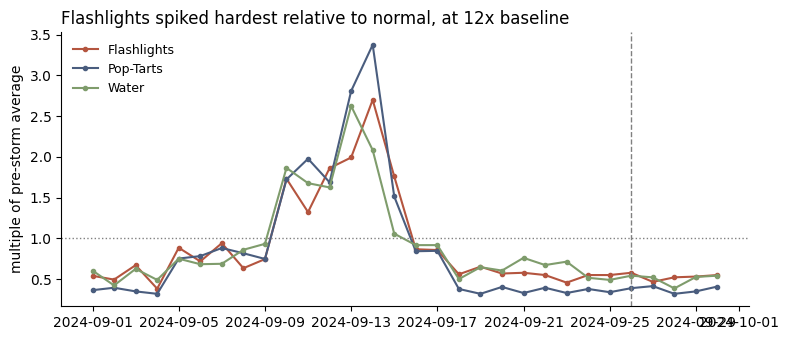

product_group
Pop-Tarts      3.4
Flashlights    2.7
Water          2.6
dtype: float64


In [6]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

In [ ]:
# TODO

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

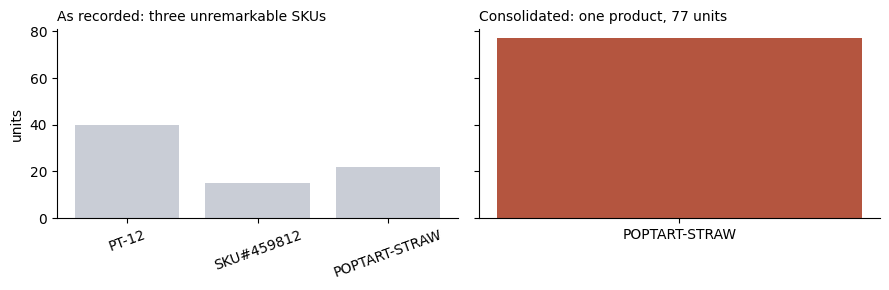

In [8]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

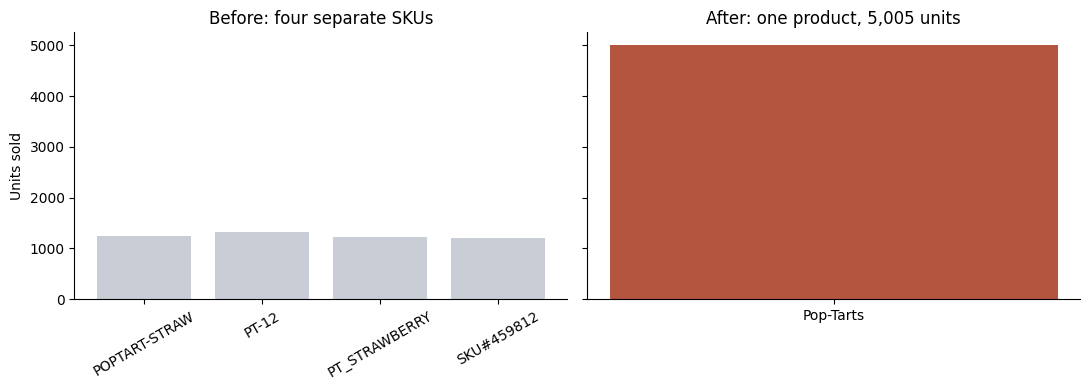

Largest individual SKU: 1332
Consolidated total: 5005
Multiple: 3.76


In [9]:
# TODO

poptart_skus = [
    "PT-12",
    "POPTART-STRAW",
    "PT_STRAWBERRY",
    "SKU#459812"
]

fragmented = (
    clean_df[clean_df["sku"].isin(poptart_skus)]
    .groupby("sku")["quantity"].sum()
)

consolidated = pd.Series({"Pop-Tarts": fragmented.sum()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].bar(fragmented.index, fragmented.values,
            color="#c9cdd6")
axes[0].set_title("Before: four separate SKUs")
axes[0].tick_params(axis="x", labelrotation=30)

axes[1].bar(consolidated.index, consolidated.values,
            color="#b4553f")
axes[1].set_title("After: one product, 5,005 units")

axes[0].set_ylabel("Units sold")

for ax in axes:
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

multiple = consolidated.iloc[0] / fragmented.max()

print("Largest individual SKU:", fragmented.max())
print("Consolidated total:", consolidated.iloc[0])
print("Multiple:", round(multiple, 2))

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

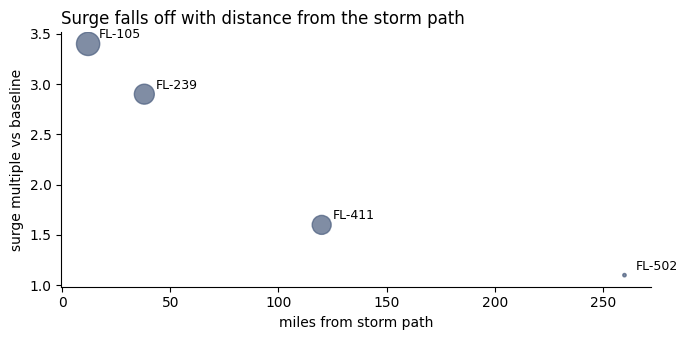

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [10]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

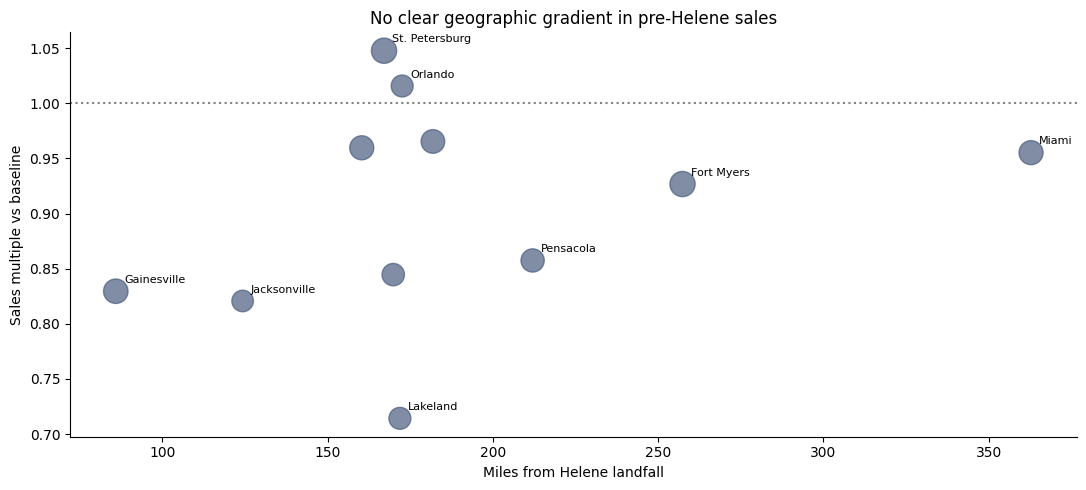

   store_id  miles_from_landfall  surge_multiple  transactions
0    FL-078                85.87            0.83            31
1    FL-105               160.29            0.96            30
2    FL-156               169.82            0.84            26
3    FL-239               172.52            1.02            25
4    FL-287               181.83            0.97            29
5    FL-302               171.84            0.71            25
6    FL-330               362.80            0.96            30
7    FL-412               124.26            0.82            24
8    FL-445               167.04            1.05            33
9    FL-501               257.35            0.93            33
11   FL-710               211.99            0.86            28


In [12]:
# TODO

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load store locations
locations = pd.read_csv("/content/store_locations.csv")

# Standardize store IDs so the tables match
sales = clean_df.copy()

sales["store_id"] = (
    sales["store_id"].str.strip().str.upper()
    .str.replace(r"^FL[-_]?(\d{3})$", r"FL-\1", regex=True)
)

locations["store_id"] = (
    locations["store_id"].str.strip().str.upper()
    .str.replace(r"^FL[-_]?(\d{3})$", r"FL-\1", regex=True)
)

locations = locations.drop_duplicates(subset="store_id")

# Select storm-related products
storm_skus = [
    "PT-12", "POPTART-STRAW", "PT_STRAWBERRY", "SKU#459812",
    "WTR-24", "WATER24PK", "WTR_24PK",
    "FLASH-01", "LED-FLASH"
]

sales = sales[sales["sku"].isin(storm_skus)].copy()
sales["date"] = sales["timestamp"].dt.normalize()

# Average daily units in each period
baseline = (
    sales[sales["date"].between("2024-09-18", "2024-09-22")]
    .groupby("store_id")["quantity"].sum()
)

storm = (
    sales[sales["date"].between("2024-09-23", "2024-09-26")]
    .groupby("store_id")
    .agg(storm_units=("quantity", "sum"),
         transactions=("quantity", "size"))
)

by_store = storm.join(baseline.rename("baseline_units"))

by_store["surge_multiple"] = (
    (by_store["storm_units"] / 4) /
    (by_store["baseline_units"] / 5)
)

# Join store geography
by_store = by_store.reset_index().merge(
    locations[["store_id", "city", "latitude", "longitude"]],
    on="store_id",
    how="left"
)

by_store = by_store.dropna(
    subset=["latitude", "longitude"]
).copy()

# Distance in miles to Helene landfall
lat1, lon1 = np.radians(30.0), np.radians(-83.7)
lat2 = np.radians(by_store["latitude"])
lon2 = np.radians(by_store["longitude"])

a = (np.sin((lat2 - lat1) / 2)**2 +
     np.cos(lat1) * np.cos(lat2) *
     np.sin((lon2 - lon1) / 2)**2)

by_store["miles_from_landfall"] = (
    3958.8 * 2 * np.arcsin(np.sqrt(a))
)

# Create bubble chart
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    by_store["miles_from_landfall"],
    by_store["surge_multiple"],
    s=by_store["transactions"] * 10,
    alpha=0.7,
    color="#4a5d7e"
)

for row in by_store.itertuples():
    if row.store_id in ["FL-078", "FL-412", "FL-302",
                        "FL-445", "FL-239", "FL-710",
                        "FL-501", "FL-330"]:
        ax.annotate(
            row.city,
            (row.miles_from_landfall, row.surge_multiple),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8
        )

ax.axhline(1.0, linestyle=":", color="gray")

ax.set_title("No clear geographic gradient in pre-Helene sales")
ax.set_xlabel("Miles from Helene landfall")
ax.set_ylabel("Sales multiple vs baseline")

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print(by_store[[
    "store_id", "miles_from_landfall",
    "surge_multiple", "transactions"
]].round(2))

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [13]:
# Checkpoint
top_product = 'Pop-Tarts'         # TODO: your biggest mover
surge_multiple = 3.4        # TODO: how many times baseline
baseline_window = 'September 1-22, 2024'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 4          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Pop-Tarts
surge multiple: 3.4
baseline window: September 1-22, 2024
charts ready: 4
